BÀI 4: PIPELINE DỰ ĐOÁN GIÁ NHÀ KC HOUSE DATA (COLAB VERSION)
Đã tải dữ liệu từ file local kc_house_data.csv

BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ ĐOÁN GIÁ NHÀ
  Tập đặc trưng        Thuật toán         MAE        RMSE     R2
   All features Gradient Boosting  80442.8856 146315.5171 0.8584
   All features     Random Forest  73185.7366 150770.3913 0.8496
   All features     Decision Tree  93167.1704 183080.3607 0.7783
Top 10 features     Random Forest  93771.4626 189150.4054 0.7633
Top 10 features Gradient Boosting  99777.1221 198255.6654 0.7400
Top 10 features     Decision Tree 106493.3412 209241.4183 0.7104
   All features  Ridge Regression 125803.0092 210620.2065 0.7066
   All features Linear Regression 125794.5148 210663.0736 0.7064
Top 10 features  Ridge Regression 139604.9554 233224.6281 0.6402
Top 10 features Linear Regression 139606.8338 233224.7743 0.6402


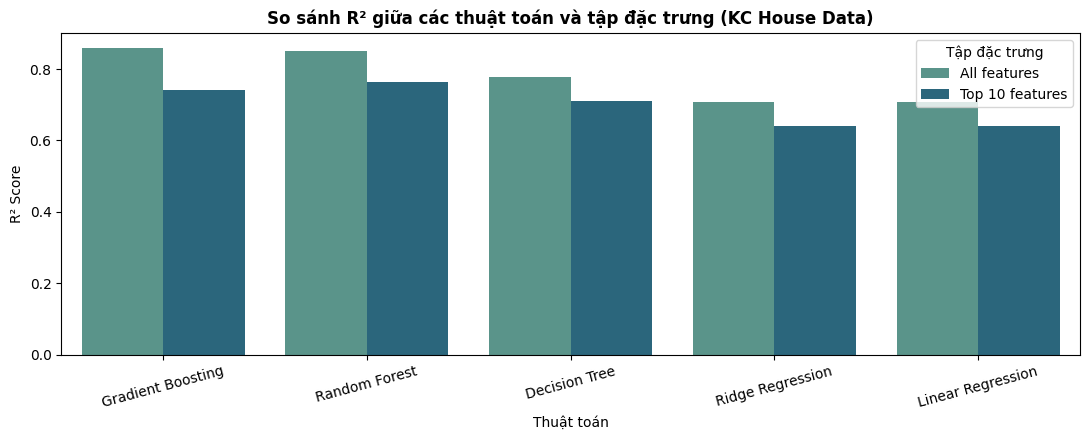

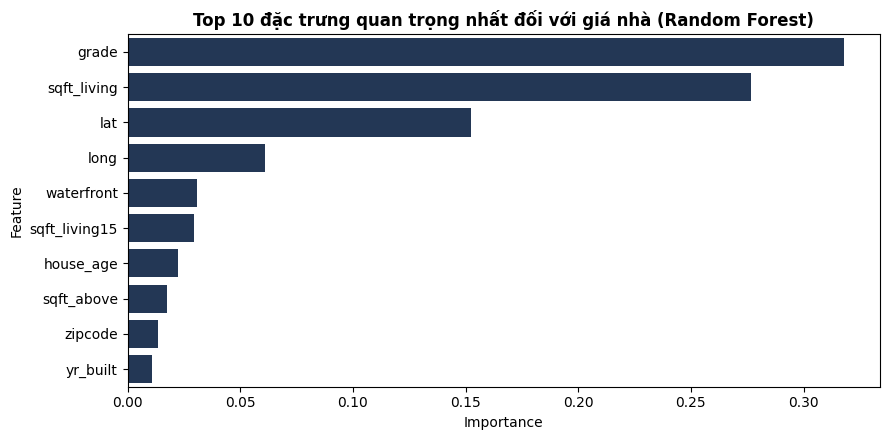


HOÀN THÀNH BÀI 4!


In [2]:
# ==============================================================================
# BÀI 4: PIPELINE DỰ ĐOÁN GIÁ NHÀ BẤT ĐỘNG SẢN KC HOUSE DATA
# Tác giả: Cấn Xuân Hồng - MSSV: 24174800181 - Lớp: DHKM18A2HN
# ==============================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

print("="*70)
print("BÀI 4: PIPELINE DỰ ĐOÁN GIÁ NHÀ KC HOUSE DATA (COLAB VERSION)")
print("="*70)

# 1. Tải bộ dữ liệu từ URL trực tiếp hoặc file local
url = "https://raw.githubusercontent.com/cxhong24174800181-hash/phan_loai_wine_quality_merged/main/kc_house_data.csv"
try:
    df = pd.read_csv("kc_house_data.csv")
    print("Đã tải dữ liệu từ file local kc_house_data.csv")
except:
    print(f"Đang tải dữ liệu từ kho lưu trữ...")
    df = pd.read_csv(url)

# 2. Data Cleaning & Feature Engineering
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price']).query("price > 0").drop_duplicates().copy()

if 'date' in df.columns:
    date_dt = pd.to_datetime(df['date'].astype(str), errors='coerce')
    df['sale_year'] = date_dt.dt.year
    df['sale_month'] = date_dt.dt.month
    df.drop(columns=['date'], inplace=True)

if 'yr_built' in df.columns:
    df['house_age'] = (df['sale_year'] - df['yr_built']).clip(lower=0)

if 'yr_renovated' in df.columns:
    renov_yr = pd.to_numeric(df['yr_renovated'], errors='coerce')
    df['renovated'] = (renov_yr.fillna(0) > 0).astype(int)
    df['years_since_renovation'] = np.where(df['renovated'] == 1, (df['sale_year'] - renov_yr).clip(lower=0), 0)

if 'sqft_living' in df.columns and 'sqft_lot' in df.columns:
    df['living_lot_ratio'] = df['sqft_living'] / df['sqft_lot'].replace(0, np.nan)

if 'bathrooms' in df.columns and 'bedrooms' in df.columns:
    df['bath_bed_ratio'] = df['bathrooms'] / df['bedrooms'].replace(0, np.nan)

y = df['price'].copy()
X = df.drop(columns=['price', 'id'], errors='ignore').select_dtypes(include=[np.number]).dropna(axis=1, how='all')

# 3. Train/Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Top 10 đặc trưng theo tương quan
top10_cols = X_train.copy().assign(price=y_train).corr()['price'].drop('price').abs().sort_values(ascending=False).head(10).index.tolist()

X_train_top = X_train[top10_cols]
X_test_top = X_test[top10_cols]

# 4. Định nghĩa các mô hình Pipeline
def get_pipelines():
    return {
        "Linear Regression": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", LinearRegression())]),
        "Ridge Regression": Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
        "Decision Tree": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42))]),
        "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42))]),
        "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2, n_jobs=-1, random_state=42))])
    }

def run_evaluation(Xtr, Xte, ytr, yte, label):
    res, preds, models_dict = [], {}, {}
    pipes = get_pipelines()
    for name, pipe in pipes.items():
        pipe.fit(Xtr, ytr)
        p = pipe.predict(Xte)
        mae = mean_absolute_error(yte, p)
        rmse = np.sqrt(mean_squared_error(yte, p))
        r2 = r2_score(yte, p)
        res.append({"Tập đặc trưng": label, "Thuật toán": name, "MAE": mae, "RMSE": rmse, "R2": r2})
        preds[name] = p
        models_dict[name] = pipe
    return res, preds, models_dict

res_all, preds_all, models_all = run_evaluation(X_train, X_test, y_train, y_test, "All features")
res_top, preds_top, models_top = run_evaluation(X_train_top, X_test_top, y_train, y_test, "Top 10 features")

# 5. Tổng hợp bảng so sánh
df_results = pd.DataFrame(res_all + res_top).sort_values(by="R2", ascending=False).reset_index(drop=True)

print("\n" + "="*80)
print("BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH DỰ ĐOÁN GIÁ NHÀ")
print("="*80)
print(df_results.round(4).to_string(index=False))

# 6. Biểu đồ so sánh R2
plt.figure(figsize=(11, 4.5))
sns.barplot(data=df_results, x="Thuật toán", y="R2", hue="Tập đặc trưng", palette="crest")
plt.title("So sánh R² giữa các thuật toán và tập đặc trưng (KC House Data)", fontsize=12, fontweight='bold')
plt.ylabel("R² Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 7. Độ quan trọng đặc trưng của RandomForest
rf_estimator = models_all["Random Forest"].named_steps["model"]
feat_imp = pd.DataFrame({"Feature": X_train.columns, "Importance": rf_estimator.feature_importances_}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=feat_imp.head(10), x="Importance", y="Feature", color="#1b365d")
plt.title("Top 10 đặc trưng quan trọng nhất đối với giá nhà (Random Forest)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nHOÀN THÀNH BÀI 4!")